In [1]:
import os

base_path = '/home/23bq1a4293/Personal/project/seg_data/meningioma/BraTS-MEN-Train'
# Get all subdirectories starting with 'BraTS-MEN'
patients = sorted([d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d)) and 'BraTS-MEN' in d])

print(f"--- Dataset Structure Summary ---")
print(f"Total Patient Folders Found: {len(patients)}")

# Check a sample patient's files
if patients:
    sample_id = patients[0]
    sample_path = os.path.join(base_path, sample_id)
    files = os.listdir(sample_path)
    print(f"\nExample Structure for {sample_id}:")
    for f in sorted(files):
        print(f"  └── {f}")

# Integrity Check
missing_files = []
for p in patients:
    expected_files = [f"{p}-t1n.nii.gz", f"{p}-t1c.nii.gz", f"{p}-t2w.nii.gz", f"{p}-t2f.nii.gz", f"{p}-seg.nii.gz"]
    for ef in expected_files:
        if not os.path.exists(os.path.join(base_path, p, ef)):
            missing_files.append(f"{p}/{ef}")

if not missing_files:
    print("\n✅ Integrity Check Passed: All 1,000 patients have all 5 required NIfTI files.")
else:
    print(f"\n❌ Warning: {len(missing_files)} files are missing!")

--- Dataset Structure Summary ---
Total Patient Folders Found: 1000

Example Structure for BraTS-MEN-00004-000:
  └── BraTS-MEN-00004-000-seg.nii.gz
  └── BraTS-MEN-00004-000-t1c.nii.gz
  └── BraTS-MEN-00004-000-t1n.nii.gz
  └── BraTS-MEN-00004-000-t2f.nii.gz
  └── BraTS-MEN-00004-000-t2w.nii.gz

✅ Integrity Check Passed: All 1,000 patients have all 5 required NIfTI files.


In [2]:
import os
import nibabel as nib
import numpy as np
patient_ids = sorted([d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))])

volumes = []
for pid in patient_ids:
    mask_path = os.path.join(base_path, pid, f"{pid}-seg.nii.gz")
    mask_data = nib.load(mask_path).get_fdata()
    # Count non-zero voxels (tumor regions)
    tumor_voxels = np.sum(mask_data > 0)
    volumes.append((pid, tumor_voxels))

# Sort by volume descending
top_cases = sorted(volumes, key=lambda x: x[1], reverse=True)[:20]

print("Top 5 Largest Tumor Distributions:")
for rank, (pid, vol) in enumerate(top_cases, 1):
    print(f"{rank}. {pid}: {vol} voxels")

Top 5 Largest Tumor Distributions:
1. BraTS-MEN-01385-000: 321447 voxels
2. BraTS-MEN-00131-000: 320547 voxels
3. BraTS-MEN-00832-000: 317968 voxels
4. BraTS-MEN-00166-000: 300095 voxels
5. BraTS-MEN-01123-000: 267737 voxels
6. BraTS-MEN-00960-000: 267314 voxels
7. BraTS-MEN-00614-000: 264894 voxels
8. BraTS-MEN-01250-000: 256530 voxels
9. BraTS-MEN-00686-000: 255183 voxels
10. BraTS-MEN-01048-000: 254512 voxels
11. BraTS-MEN-00220-000: 248719 voxels
12. BraTS-MEN-00425-000: 244831 voxels
13. BraTS-MEN-01298-000: 242776 voxels
14. BraTS-MEN-00621-000: 242708 voxels
15. BraTS-MEN-00655-000: 236681 voxels
16. BraTS-MEN-00545-000: 235956 voxels
17. BraTS-MEN-00176-000: 232262 voxels
18. BraTS-MEN-00488-000: 228339 voxels
19. BraTS-MEN-00909-000: 225376 voxels
20. BraTS-MEN-01382-000: 224496 voxels


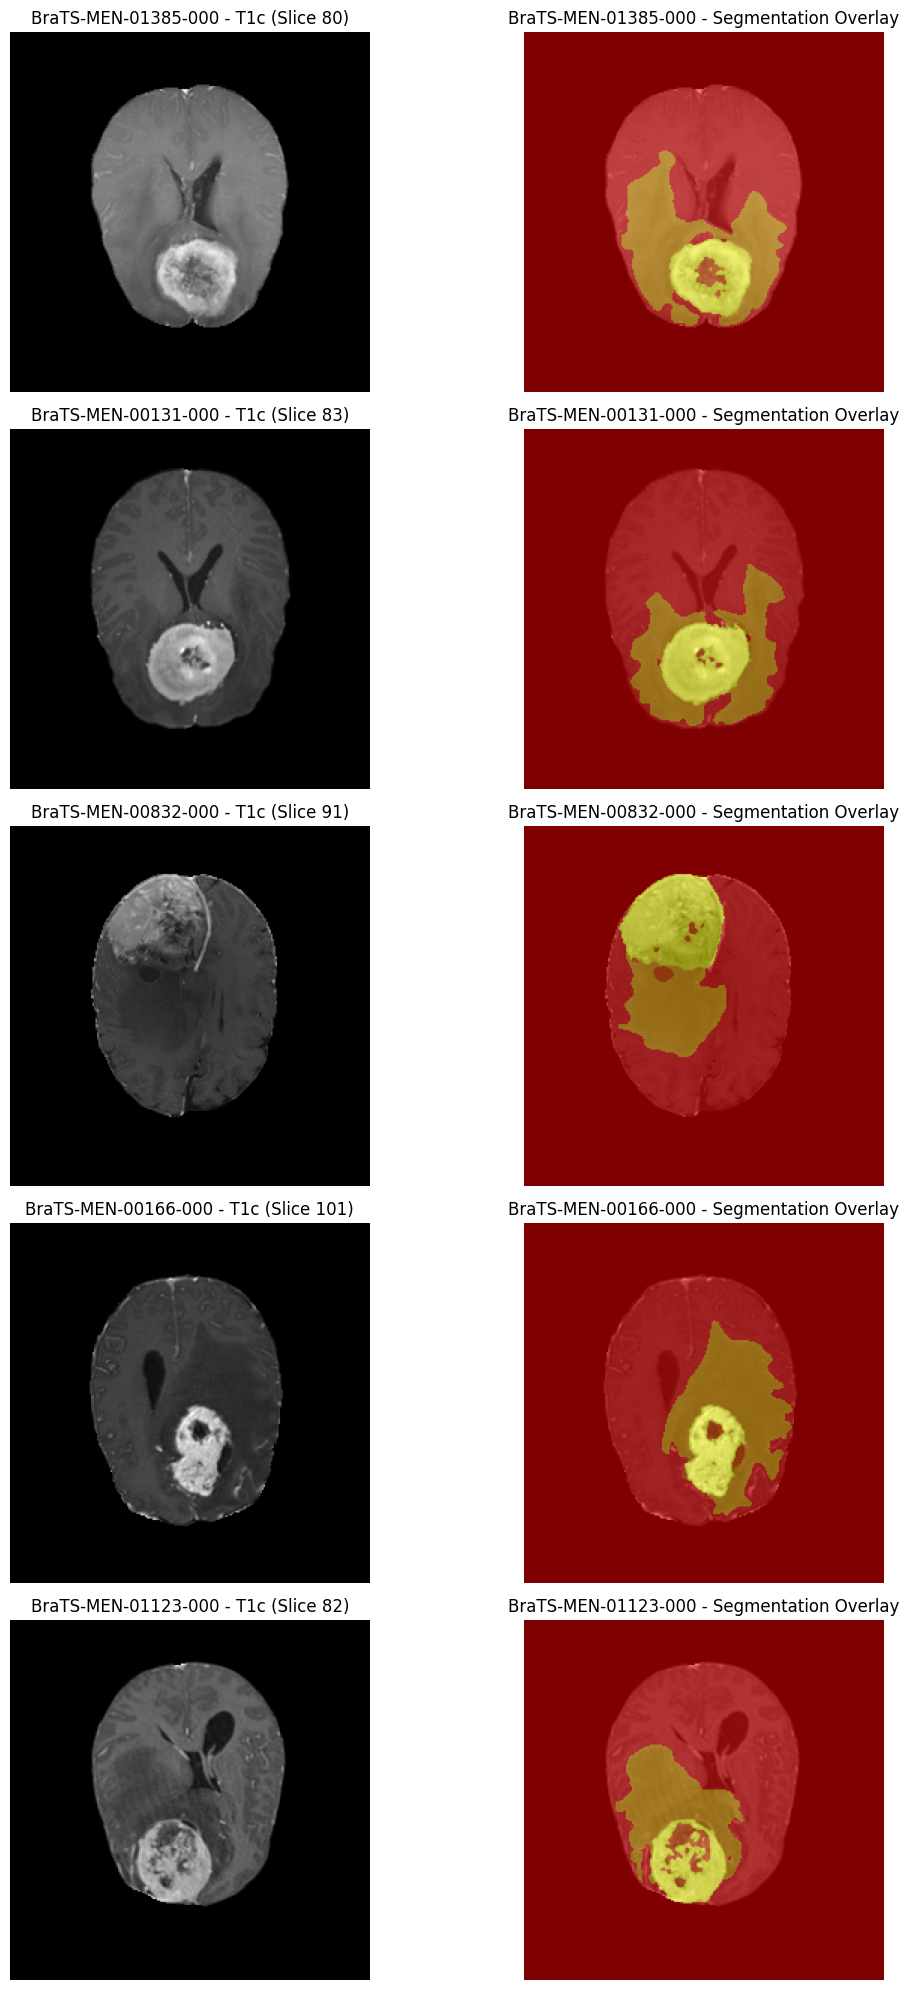

In [3]:
import os
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np

top_pids = [
    "BraTS-MEN-01385-000", "BraTS-MEN-00131-000", 
    "BraTS-MEN-00832-000", "BraTS-MEN-00166-000", 
    "BraTS-MEN-01123-000"
]

fig, axes = plt.subplots(len(top_pids), 2, figsize=(12, 4 * len(top_pids)))

for i, pid in enumerate(top_pids):
    # Load T1-Contrast and Mask
    img = nib.load(os.path.join(base_path, pid, f"{pid}-t1c.nii.gz")).get_fdata()
    mask = nib.load(os.path.join(base_path, pid, f"{pid}-seg.nii.gz")).get_fdata()
    
    # Find slice with maximum tumor area
    best_slice = np.argmax(np.sum(mask, axis=(0, 1)))
    
    # Plot Raw T1c
    axes[i, 0].imshow(img[:, :, best_slice].T, cmap='gray', origin='lower')
    axes[i, 0].set_title(f"{pid} - T1c (Slice {best_slice})")
    axes[i, 0].axis('off')
    
    # Plot Mask Overlay
    axes[i, 1].imshow(img[:, :, best_slice].T, cmap='gray', origin='lower')
    axes[i, 1].imshow(mask[:, :, best_slice].T, cmap='autumn', alpha=0.5, origin='lower')
    axes[i, 1].set_title(f"{pid} - Segmentation Overlay")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

Analyzing distribution for 1000 patients...


  0%|          | 3/1000 [00:00<04:13,  3.93it/s]

100%|██████████| 1000/1000 [04:14<00:00,  3.92it/s]


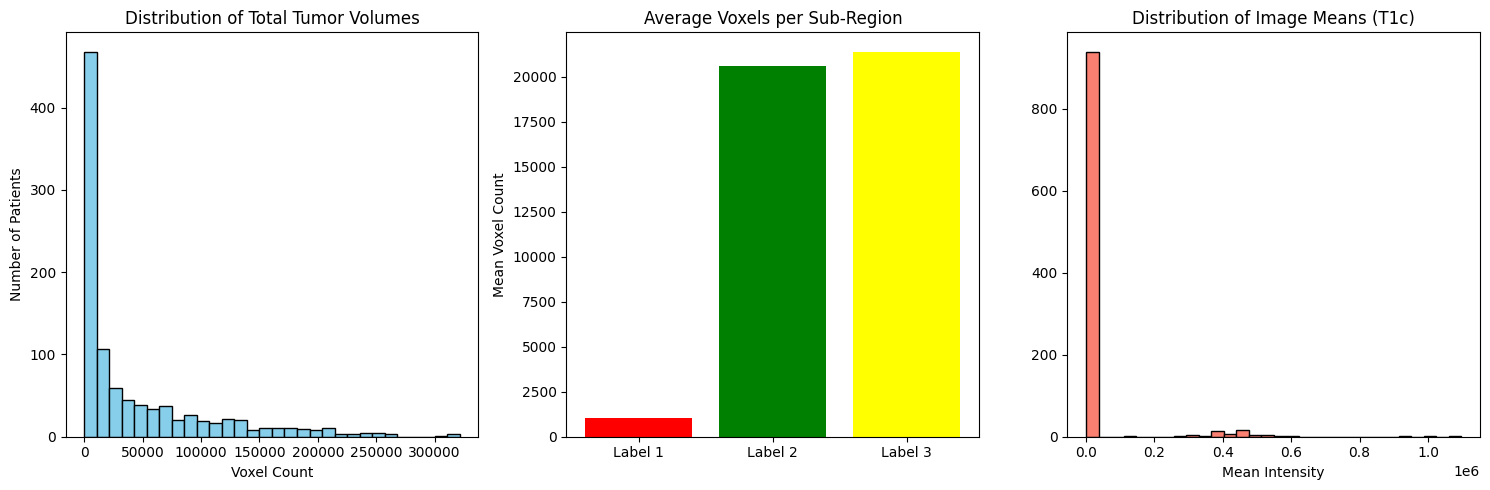


--- Global Data Distribution Summary ---
Average Tumor Volume: 43047.23 voxels
Label Ratio (1:2:3): 1063341:20591044:21392841


In [4]:
import os
import nibabel as nib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm

# Configuration
patient_ids = sorted([d for d in os.listdir(base_path) if os.path.isdir(os.path.join(base_path, d))])

# Storage for results
stats = []

print(f"Analyzing distribution for {len(patient_ids)} patients...")

for pid in tqdm(patient_ids):
    # 1. Label Distribution (from -seg.nii.gz)
    mask_path = os.path.join(base_path, pid, f"{pid}-seg.nii.gz")
    mask = nib.load(mask_path).get_fdata()
    
    # BraTS Labels: 1 (Necrotic), 2 (Edema), 3 (Enhancing Tumor)
    counts = {
        'pid': pid,
        'label_1_voxels': np.sum(mask == 1),
        'label_2_voxels': np.sum(mask == 2),
        'label_3_voxels': np.sum(mask == 3),
        'total_tumor_voxels': np.sum(mask > 0)
    }
    
    # 2. Intensity Distribution (from -t1c.nii.gz as a sample modality)
    img_path = os.path.join(base_path, pid, f"{pid}-t1c.nii.gz")
    img = nib.load(img_path).get_fdata()
    
    # Get stats only for brain region (non-zero intensities)
    brain_voxels = img[img > 0]
    if len(brain_voxels) > 0:
        counts['img_mean'] = np.mean(brain_voxels)
        counts['img_std'] = np.std(brain_voxels)
        counts['img_max'] = np.max(brain_voxels)
    
    stats.append(counts)

# Convert to DataFrame for easy analysis
df = pd.DataFrame(stats)

# --- Summary Visualizations ---
plt.figure(figsize=(15, 5))

# Plot 1: Distribution of Tumor Volumes
plt.subplot(1, 3, 1)
plt.hist(df['total_tumor_voxels'], bins=30, color='skyblue', edgecolor='black')
plt.title('Distribution of Total Tumor Volumes')
plt.xlabel('Voxel Count')
plt.ylabel('Number of Patients')

# Plot 2: Class Imbalance (Labels 1, 2, 3)
plt.subplot(1, 3, 2)
label_means = [df['label_1_voxels'].mean(), df['label_2_voxels'].mean(), df['label_3_voxels'].mean()]
plt.bar(['Label 1', 'Label 2', 'Label 3'], label_means, color=['red', 'green', 'yellow'])
plt.title('Average Voxels per Sub-Region')
plt.ylabel('Mean Voxel Count')

# Plot 3: Intensity Means (for Normalization)
plt.subplot(1, 3, 3)
plt.hist(df['img_mean'], bins=30, color='salmon', edgecolor='black')
plt.title('Distribution of Image Means (T1c)')
plt.xlabel('Mean Intensity')

plt.tight_layout()
plt.show()

# Print Global Averages
print("\n--- Global Data Distribution Summary ---")
print(f"Average Tumor Volume: {df['total_tumor_voxels'].mean():.2f} voxels")
print(f"Label Ratio (1:2:3): {df['label_1_voxels'].sum()}:{df['label_2_voxels'].sum()}:{df['label_3_voxels'].sum()}")

In [5]:
import nibabel as nib
import numpy as np

seg = nib.load("/home/23bq1a4293/Personal/project/seg_data/meningioma/BraTS-MEN-Train/BraTS-MEN-01382-000/BraTS-MEN-01382-000-seg.nii.gz").get_fdata()
print("Unique labels:", np.unique(seg))

Unique labels: [0. 1. 2. 3.]


In [6]:

features = infer_and_visualize("/home/23bq1a4293/Personal/project/seg_data/meningioma/BraTS-MEN-Train/BraTS-MEN-01385-000")

print(features["shape_Volume_mm3"])
print(features["firstorder_Entropy"])

NameError: name 'infer_and_visualize' is not defined

In [ ]:
import sys
!{sys.executable} -m pip install nibabel pydicom SimpleITK --quiet

In [ ]:
import os
import torch
import nibabel as nib
import numpy as np
from tqdm import tqdm
from torch.utils.data import Dataset, DataLoader
from monai.networks.nets import SegResNet
from monai.inferers import sliding_window_inference
from monai.transforms import (
    Compose, Orientationd, ScaleIntensityRanged, EnsureTyped, AsDiscreted
)

# ================= CONFIG =================
dataset_root = "/home/23bq1a4293/Personal/project/seg_data/meningioma/BraTS-MEN-Train"
test_file    = "test_patients.txt"
model_path   = "/home/23bq1a4293/Personal/project/models/Segmentation/men/best_model_smoothed_4class.pth"
output_dir   = "./inference_outputs"

device      = torch.device("cuda" if torch.cuda.is_available() else "cpu")
patch_size  = (192, 192, 128)
NUM_CLASSES = 4

os.makedirs(output_dir, exist_ok=True)

# ================= LOAD DATA =================
with open(test_file) as f:
    patient_ids = [l.strip() for l in f if l.strip()]

inference_data = []
for pid in patient_ids:
    case_path = os.path.join(dataset_root, pid)
    paths = {m: os.path.join(case_path, f"{pid}-{m}.nii.gz") 
             for m in ["t1c", "t1n", "t2f", "t2w"]}
    if all(os.path.exists(p) for p in paths.values()):
        inference_data.append({"paths": paths, "pid": pid})
    else:
        print(f"Skipping {pid}: missing modality")

print(f"Total valid cases: {len(inference_data)}")

# ================= CUSTOM DATASET =================
class MenDataset(Dataset):
    def __init__(self, data):
        self.data = data

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        vols = []
        affine = None
        for m in ["t1c", "t1n", "t2f", "t2w"]:
            img = nib.load(item["paths"][m])
            if affine is None:
                affine = img.affine
                header = img.header
            arr = img.get_fdata(dtype=np.float32)
            # Normalize to [0, 1]
            arr = np.clip(arr, 0, 3000) / 3000.0
            vols.append(arr)
        
        # Stack to (4, H, W, D)
        volume = np.stack(vols, axis=0)
        return {
            "image": torch.from_numpy(volume).float(),
            "affine": torch.from_numpy(affine).float(),
            "pid": item["pid"],
            "ref_path": item["paths"]["t1c"]
        }

infer_ds     = MenDataset(inference_data)
infer_loader = DataLoader(infer_ds, batch_size=1, shuffle=False, 
                          num_workers=0, pin_memory=False)

# ================= MODEL =================
model = SegResNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=NUM_CLASSES,
    init_filters=32
).to(device)

print(f"Loading weights from: {model_path}")
model.load_state_dict(torch.load(model_path, map_location=device, weights_only=True))
model.eval()

# ================= INFERENCE =================
print("Starting inference...")

with torch.no_grad():
    for batch_data in tqdm(infer_loader, desc="Inferring"):
        inputs = batch_data["image"].to(device)
        pid    = batch_data["pid"][0]
        affine = batch_data["affine"][0].numpy()

        with torch.amp.autocast('cuda'):
            outputs = sliding_window_inference(
                inputs,
                roi_size=patch_size,
                sw_batch_size=4,
                predictor=model,
                overlap=0.5
            )

        # Argmax to get label map
        pred = torch.argmax(outputs, dim=1).squeeze(0).cpu().numpy().astype(np.uint8)

        # Save as nii.gz using reference affine
        ref = nib.load(batch_data["ref_path"][0])
        out_img = nib.Nifti1Image(pred, ref.affine, ref.header)
        out_path = os.path.join(output_dir, f"{pid}_seg_pred.nii.gz")
        nib.save(out_img, out_path)
        print(f"  Saved: {out_path}")

print(f"\nInference complete! Saved to: {output_dir}")

/home/23bq1a4293/.local/lib/python3.11/site-packages/requests/__init__.py:113: RequestsDependencyWarning: urllib3 (2.0.7) or chardet (6.0.0.post1)/charset_normalizer (2.0.4) doesn't match a supported version!
  warnings.warn(
<frozen importlib._bootstrap_external>:1241: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.


Total valid cases: 1
Loading weights from: /home/23bq1a4293/Personal/project/models/Segmentation/men/best_model_smoothed_4class.pth
Starting inference...


Inferring:   0%|          | 0/1 [00:00<?, ?it/s]Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
Inferring: 100%|██████████| 1/1 [00:01<00:00,  1.85s/it]

  Saved: ./inference_outputs/BraTS-MEN-01123-000_seg_pred.nii.gz

Inference complete! Saved to: ./inference_outputs


In [7]:
%matplotlib inline
import os
import nibabel as nib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from ipywidgets import interact, IntSlider
from IPython.display import clear_output

# ================= CONFIG =================

dataset_root = "/home/23bq1a4293/Personal/project/seg_data/meningioma/BraTS-MEN-Train"
patient_id   = "BraTS-MEN-01123-000"
output_dir   = "./inference_outputs"

pred_file_name = f"{patient_id}_seg_pred.nii.gz"

image_path = os.path.join(dataset_root, patient_id, f"{patient_id}-t1c.nii.gz")
gt_path    = os.path.join(dataset_root, patient_id, f"{patient_id}-seg.nii.gz")
pred_path  = os.path.join(output_dir, pred_file_name)

# ================= LOAD DATA =================

for p in [image_path, gt_path, pred_path]:
    if not os.path.exists(p):
        raise FileNotFoundError(f"Not found: {p}")

img_data  = nib.load(image_path).get_fdata()
gt_data   = nib.load(gt_path).get_fdata()
pred_data = nib.load(pred_path).get_fdata()

# ================= AUTO BEST SLICE =================
# find slice with most predicted tumor voxels

tumor_per_slice = (pred_data > 0).sum(axis=(0, 1))   # shape: (num_slices,)
best_slice      = int(np.argmax(tumor_per_slice))
print(f"Best slice (most predicted tumor): {best_slice}  "
      f"({int(tumor_per_slice[best_slice])} tumor voxels)")

# also report GT best slice for comparison
gt_per_slice  = (gt_data > 0).sum(axis=(0, 1))
gt_best_slice = int(np.argmax(gt_per_slice))
print(f"GT best slice (most GT tumor):     {gt_best_slice}  "
      f"({int(gt_per_slice[gt_best_slice])} tumor voxels)")

# ================= COLORMAP =================

colors = [(0, 0, 0, 0), 'red', 'green', 'yellow']
cmap   = mcolors.ListedColormap(colors)
bounds = [0, 1, 2, 3, 4]
norm   = mcolors.BoundaryNorm(bounds, cmap.N)

# ================= PLOT FUNCTION =================

def plot_slice(slice_idx):
    clear_output(wait=True)

    img_slice  = img_data[:, :, slice_idx]
    gt_slice   = gt_data[:, :, slice_idx]
    pred_slice = pred_data[:, :, slice_idx]

    pred_vox = int((pred_slice > 0).sum())
    gt_vox   = int((gt_slice   > 0).sum())

    fig, axes = plt.subplots(1, 4, figsize=(22, 5))

    # 1. Original T1c
    axes[0].imshow(img_slice.T, cmap="gray", origin="lower")
    axes[0].set_title(f"Original T1c (Slice {slice_idx})", fontsize=11)
    axes[0].axis("off")

    # 2. Ground Truth overlay
    axes[1].imshow(img_slice.T, cmap="gray", origin="lower")
    axes[1].imshow(gt_slice.T, cmap=cmap, norm=norm, origin="lower", alpha=0.6)
    axes[1].set_title(f"Ground Truth  [{gt_vox} vox]", fontsize=11)
    axes[1].axis("off")

    # 3. Prediction overlay
    axes[2].imshow(img_slice.T, cmap="gray", origin="lower")
    axes[2].imshow(pred_slice.T, cmap=cmap, norm=norm, origin="lower", alpha=0.6)
    axes[2].set_title(f"Prediction  [{pred_vox} vox]", fontsize=11)
    axes[2].axis("off")

    # 4. Prediction mask only
    axes[3].imshow(pred_slice.T, cmap=cmap, norm=norm, origin="lower")
    axes[3].set_title("Predicted Mask Only", fontsize=11)
    axes[3].axis("off")

    # legend
    import matplotlib.patches as mpatches
    legend = [
        mpatches.Patch(color='red',    label='Necrotic Core'),
        mpatches.Patch(color='green',  label='Peritumoral Edema'),
        mpatches.Patch(color='yellow', label='Enhancing Tumor'),
    ]
    fig.legend(handles=legend, loc="lower center", ncol=3,
               fontsize=10, frameon=True, bbox_to_anchor=(0.5, -0.05))

    # mark best slice
    marker = " ◀ BEST" if slice_idx == best_slice else ""
    plt.suptitle(f"{patient_id}  |  Slice {slice_idx}{marker}",
                 fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

# ================= INTERACTIVE WIDGET =================

max_slice = img_data.shape[2] - 1

interact(
    plot_slice,
    slice_idx=IntSlider(
        min=0,
        max=max_slice,
        step=1,
        value=best_slice,        # ← starts at best slice automatically
        description="Z-Slice:",
        continuous_update=False
    )
)

Best slice (most predicted tumor): 82  (5806 tumor voxels)
GT best slice (most GT tumor):     82  (5739 tumor voxels)


interactive(children=(IntSlider(value=82, continuous_update=False, description='Z-Slice:', max=154), Output())…

<function __main__.plot_slice(slice_idx)>

In [1]:
%matplotlib inline
import os
import nibabel as nib
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import ipywidgets as widgets
from IPython.display import display, clear_output

from monai.networks.nets import SegResNet
from monai.inferers import sliding_window_inference
from monai.metrics import DiceMetric
from monai.transforms import AsDiscrete

# ================= CONFIG =================
dataset_root = "/home/23bq1a4293/Personal/project/seg_data/meningioma/BraTS-MEN-Train"
unused_file  = "unused_patients.txt"
sampled_file = "sampled_300_patients.txt"
checkpoint   = "/home/23bq1a4293/Personal/project/models/Segmentation/men/best_model_smoothed_4class.pth"

patch_size  = (192, 192, 128)
NUM_CLASSES = 4
device      = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ================= COLORMAP =================
colors = [(0, 0, 0, 0), 'red', 'green', 'yellow']
cmap   = mcolors.ListedColormap(colors)
bounds = [0, 1, 2, 3, 4]
norm   = mcolors.BoundaryNorm(bounds, cmap.N)
legend_patches = [
    mpatches.Patch(color='red',    label='Necrotic Core'),
    mpatches.Patch(color='green',  label='Peritumoral Edema'),
    mpatches.Patch(color='yellow', label='Enhancing Tumor'),
]

# ================= LOAD MODEL ONCE =================
model = SegResNet(
    spatial_dims=3, in_channels=4,
    out_channels=NUM_CLASSES, init_filters=32
).to(device)
model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
model.eval()
print(f"✅ Model loaded: {checkpoint}")

# ================= DIRECT NIBABEL LOADER =================
def load_case(pid):
    """Load all modalities + label directly with nibabel, returns tensors."""
    case_path = os.path.join(dataset_root, pid)
    modalities = ["t1c", "t1n", "t2f", "t2w"]
    
    vols = []
    for m in modalities:
        path = os.path.join(case_path, f"{pid}-{m}.nii.gz")
        arr  = nib.load(path).get_fdata(dtype=np.float32)
        arr  = np.clip(arr, 0, 3000) / 3000.0  # normalize
        vols.append(arr)
    
    # Stack → (4, H, W, D)
    image = np.stack(vols, axis=0)
    
    # Load label
    label_path = os.path.join(case_path, f"{pid}-seg.nii.gz")
    label = nib.load(label_path).get_fdata(dtype=np.float32).astype(np.uint8)
    
    return image, label  # (4,H,W,D), (H,W,D)

# ================= PICK PATIENTS =================
with open(unused_file) as f:
    all_unused = [l.strip() for l in f if l.strip()]
with open(sampled_file) as f:
    already_used = set(l.strip() for l in f if l.strip())

strictly_unused = sorted([p for p in all_unused if p not in already_used])
print(f"✅ {len(strictly_unused)} strictly unseen patients available")

# ================= CACHE =================
inference_cache = {}

def run_inference(pid):
    if pid in inference_cache:
        return inference_cache[pid]

    image_np, label_np = load_case(pid)

    # (4,H,W,D) → (1,4,H,W,D)
    image_tensor = torch.from_numpy(image_np).float().unsqueeze(0).to(device)

    with torch.no_grad():
        out = sliding_window_inference(
            image_tensor, roi_size=patch_size,
            sw_batch_size=1, predictor=model, overlap=0.25
        )

    pred_np = torch.argmax(out, dim=1)[0].cpu().numpy().astype(np.uint8)
    gt_np   = label_np

    # Per-class Dice
    post_pred  = AsDiscrete(argmax=False, to_onehot=NUM_CLASSES)
    post_label = AsDiscrete(to_onehot=NUM_CLASSES)
    dm = DiceMetric(include_background=False, reduction="none")
    p  = post_pred(torch.from_numpy(pred_np).unsqueeze(0))
    g  = post_label(torch.from_numpy(gt_np).unsqueeze(0).long())
    dm([p], [g])
    per_class = [0.0 if np.isnan(v) else v for v in dm.aggregate()[0].tolist()]
    dm.reset()

    result = {
        "t1c":       image_np[0],   # (H,W,D)
        "t2f":       image_np[2],
        "gt":        gt_np,
        "pred":      pred_np,
        "dice":      per_class,
        "mean_dice": float(np.mean(per_class)),
        "num_slices": pred_np.shape[2],
        "best_slice": int(np.argmax(
            (gt_np > 0).sum(axis=(0, 1)) if gt_np.sum() > 0
            else (pred_np > 0).sum(axis=(0, 1))
        )),
    }
    inference_cache[pid] = result
    return result

# ================= WIDGETS =================
patient_dropdown = widgets.Dropdown(
    options=strictly_unused,
    description="Patient:",
    layout=widgets.Layout(width="350px"),
    style={"description_width": "70px"},
)

slice_slider = widgets.IntSlider(
    min=0, max=154, step=1, value=77,
    description="Z-Slice:",
    continuous_update=False,
    layout=widgets.Layout(width="500px"),
    style={"description_width": "70px"},
)

modality_toggle = widgets.ToggleButtons(
    options=["T1c", "T2-FLAIR"],
    description="Modality:",
    style={"description_width": "70px"},
)

run_button = widgets.Button(
    description="▶  Run Inference",
    button_style="success",
    layout=widgets.Layout(width="160px", height="35px"),
)

best_slice_button = widgets.Button(
    description="⚡ Best Slice",
    button_style="info",
    layout=widgets.Layout(width="130px", height="35px"),
)

dice_label = widgets.HTML(value="<b>Dice:</b> run inference first")
output     = widgets.Output()

# ================= PLOT =================
def plot_current(pid, slice_idx, modality):
    if pid not in inference_cache:
        with output:
            clear_output(wait=True)
            print(f"⏳ Click '▶ Run Inference' to process {pid}")
        return

    r       = inference_cache[pid]
    img_np  = r["t1c"] if modality == "T1c" else r["t2f"]
    img_sl  = img_np[:, :, slice_idx]
    gt_sl   = r["gt"][:, :, slice_idx]
    pred_sl = r["pred"][:, :, slice_idx]

    with output:
        clear_output(wait=True)
        fig, axes = plt.subplots(1, 5, figsize=(26, 5))

        axes[0].imshow(img_sl.T, cmap="gray", origin="lower")
        axes[0].set_title(f"{modality} (Slice {slice_idx})", fontsize=11)
        axes[0].axis("off")

        axes[1].imshow(img_sl.T, cmap="gray", origin="lower")
        axes[1].imshow(gt_sl.T,  cmap=cmap, norm=norm, origin="lower", alpha=0.65)
        axes[1].set_title("Ground Truth", fontsize=11)
        axes[1].axis("off")

        axes[2].imshow(img_sl.T,  cmap="gray", origin="lower")
        axes[2].imshow(pred_sl.T, cmap=cmap, norm=norm, origin="lower", alpha=0.65)
        axes[2].set_title("Prediction", fontsize=11)
        axes[2].axis("off")

        axes[3].set_facecolor("black")
        axes[3].imshow(gt_sl.T, cmap=cmap, norm=norm, origin="lower")
        axes[3].set_title("GT Mask", fontsize=11)
        axes[3].axis("off")

        axes[4].set_facecolor("black")
        axes[4].imshow(pred_sl.T, cmap=cmap, norm=norm, origin="lower")
        axes[4].set_title("Pred Mask", fontsize=11)
        axes[4].axis("off")

        fig.legend(handles=legend_patches, loc="lower center",
                   ncol=3, fontsize=10, frameon=True, bbox_to_anchor=(0.5, -0.05))
        d = r["dice"]
        plt.suptitle(
            f"{pid}  |  Slice {slice_idx}  |  "
            f"Mean Dice: {r['mean_dice']:.4f}  "
            f"Nec: {d[0]:.3f}  Ede: {d[1]:.3f}  Enh: {d[2]:.3f}",
            fontsize=12, fontweight="bold"
        )
        plt.tight_layout()
        plt.show()

# ================= CALLBACKS =================
def on_run_clicked(b):
    pid = patient_dropdown.value
    run_button.description = "⏳ Running..."
    run_button.disabled    = True
    result = run_inference(pid)
    slice_slider.max   = result["num_slices"] - 1
    slice_slider.value = result["best_slice"]
    dice_label.value = (
        f"<b>Mean Dice: {result['mean_dice']:.4f}</b> &nbsp;|&nbsp; "
        f"Necrotic: {result['dice'][0]:.3f} &nbsp; "
        f"Edema: {result['dice'][1]:.3f} &nbsp; "
        f"Enhancing: {result['dice'][2]:.3f}"
    )
    run_button.description = "▶  Run Inference"
    run_button.disabled    = False
    plot_current(pid, slice_slider.value, modality_toggle.value)

def on_best_slice(b):
    pid = patient_dropdown.value
    if pid in inference_cache:
        slice_slider.value = inference_cache[pid]["best_slice"]

def on_slice_change(change):
    plot_current(patient_dropdown.value, change["new"], modality_toggle.value)

def on_modality_change(change):
    plot_current(patient_dropdown.value, slice_slider.value, change["new"])

run_button.on_click(on_run_clicked)
best_slice_button.on_click(on_best_slice)
slice_slider.observe(on_slice_change, names="value")
modality_toggle.observe(on_modality_change, names="value")

# ================= LAYOUT =================
controls = widgets.VBox([
    widgets.HBox([patient_dropdown, run_button, best_slice_button]),
    widgets.HBox([slice_slider, modality_toggle]),
    dice_label,
])

display(controls, output)


✅ Model loaded: /home/23bq1a4293/Personal/project/models/Segmentation/men/best_model_smoothed_4class.pth
✅ 300 strictly unseen patients available


Output()